# Phase 3 — Asset screening

**Goal.** Keep only the assets where the strategy has a real chance. Six filters, every cutoff fixed before any result was looked at. The screen is a function, `screen(panel, ohlc, asof)`, that reads only data up to `asof`. Phase 7's walk-forward calls it once a year, so an asset enters the portfolio only after it has passed on past data.

Development sample only (1926–2018). The 2019+ holdout is never loaded here.

### Key findings

1. **Two of seven factors survive on the full development sample: market (SPY) and momentum (MTUM).** Betting-against-beta also passes every filter on the factor side, and shows the falling reward per unit of risk of Phase 2, but its stand-in ETF, USMV, fails filter 4.
2. **Filter 3, the exploitable link, does most of the cutting.** Four of the five cut factors fail it; the fifth is betting-against-beta (item 3). Size and investment show no link at all (alpha −0.6% and +0.2%). Value and profitability have positive alpha, but their reward per unit of risk does not fall steadily as risk rises.
3. **Filter 4 (systematic risk) can now fail, and it does.** The first version regressed the raw ETF on the factors and could not fail: every ETF scored 0.82–0.96, mostly market beta. The filter now hedges the market out first and tests the leftover tilt against a cutoff of 0.5. SPY (the market itself) scores 0.96, MTUM 0.53, USMV 0.38 and QUAL 0.17. **USMV is cut, so betting-against-beta has no tradeable stand-in.** MTUM clears the cutoff only narrowly.
4. **Liquidity matters.** QUAL trades $29 million a day against the $50 million cutoff and is cut. In real time, USMV would first pass the liquidity rule at the end of 2016 and MTUM only at the end of 2018.
5. **The bid-ask spread rule is not applied.** The data has no quotes, and the best proxy from daily high and low prices reads 7–15 bp for SPY, whose real spread is about 1 bp. So filter 5 gates on dollar volume only, and spreads stay unverified until the cost phase.
6. **Screened in real time, assets are admitted late and unevenly.** Apart from a one-year accident for momentum in 1936, no factor is admitted at any year-end before 1983. Only 25 of 83 year-ends admit anything, and at 1960 and 1980 the portfolio would have been empty. Momentum is held out until 2009 by filter 1: its level φ sat between 0.24 and 0.46 for seventy years and only crossed 0.5 in 2009.
7. **Five decisions are left open for Phase 7:** what to hold when nothing passes, how to handle assets that flip in and out, how to run the long history without ETFs, whether momentum's filter-1 cutoff should use log variance, and what to do about betting-against-beta now that USMV is cut. They are listed at the end.

### How to read this notebook

Each filter has the same parts: **what and why**, the **rule**, the **result** (table and plot), and what it **decides**. Numbers quoted in the text refer to the build of 2026-10-17; the tables and plots are recomputed every time the notebook runs.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch, Rectangle

from src import screen as sc
from src import variance as v
from src.data.load import load_dev, load_etf_ohlc_dev

pd.set_option("display.float_format", "{:,.3f}".format, "display.max_columns", 30, "display.width", 200,
              "display.max_colwidth", None)

NAMES = {"mkt": "Market", "smb": "Size", "hml": "Value", "mom": "Momentum", "rmw": "Profitability",
         "cma": "Investment", "bab": "Betting against beta"}
COLORS = {"mkt": "#2a78d6", "smb": "#eb6834", "hml": "#1baf7a", "mom": "#eda100", "rmw": "#e87ba4",
          "cma": "#008300", "bab": "#4a3aa7"}
ETF_COLORS = {sc.ETF_FOR[f]: COLORS[f] for f in sc.ETF_FOR}
ERA_COLORS = ["#86b6ef", "#2a78d6", "#104281"]            # one hue, light to dark: eras are ordered in time
PASS, FAIL, DARK = "#b7d3f6", "#e8e7e1", "#1c5cab"
INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "lines.linewidth": 1.5, "font.size": 8.5, "axes.titlesize": 9.5, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110,
})

panel, ohlc = load_dev(), load_etf_ohlc_dev()           # development sample only
ASOF = panel.index[-1]                                    # 2018-12-31
final = sc.screen(panel, ohlc, ASOF)
print(f"Development sample: {panel.index[0].date()} to {ASOF.date()}")

Development sample: 1926-07-01 to 2018-12-31


## 1. The rules (fixed before looking)

| # | Filter | Test | Pass rule | Applies to |
|---|---|---|---|---|
| 1 | Predictable risk | Phase 2 Test 1 | Ljung-Box rejects at 1% at 20 and 60 lags, **and** monthly φ > 0.5 | factor |
| 2 | Risk that moves | standard deviation of log RV | **no cutoff**: rank it, use as a tie-breaker | factor |
| 3 | Exploitable link | Phase 2 Test 4 | reward per unit of risk falls with risk (rank correlation ≤ −0.7 and lower in the wildest quintile than the calmest), **and** spanning α > 0 with t > 1.96 | factor |
| 4 | Systematic risk | R² of the market-hedged ETF on market, size, value, momentum and BAB | R² > 0.5 | ETF |
| 5 | Tradeable | median daily dollar volume over the last 252 trading days | > $50 million (the bid-ask half of the rule is not applied; see filter 5 in Section 2) | ETF |
| 6 | Stable | Phase 2 Test 6 | spanning α > 0 in every era | factor |

**Choices I had to make** (the spec leaves them open). Each is written into the code before any result:

- **Eras for filter 6.** The history so far is cut into three equal-length parts. Phase 2 used fixed calendar eras, but in real time the last calendar era may be only a few years long. Equal parts adapt to however much history exists.
- **Minimum history.** A factor needs 120 months (10 years) of complete data before it can be screened, so each era has at least 40 months. An ETF needs 252 trading days (one year) for filters 4 and 5.
- **Expanding window.** Filters use all history up to the as-of date. More data makes alpha and persistence estimates steadier. Phase 2 found drifting persistence, which filter 6 and the yearly re-screen guard against.
- **ETF stand-ins.** Filters 4 and 5 need a tradeable ETF per factor. The four ETFs in the data map to market → SPY, momentum → MTUM, profitability → QUAL, betting-against-beta → USMV. The last two are loose matches (QUAL is a quality ETF, USMV is minimum volatility). Size, value and investment have no ETF in the data, so they cannot pass filters 4 and 5.
- **Filter 4 hedges the market first.** The ETF's daily excess return minus its market beta times the market return (beta from the data up to the as-of date), regressed on market, size, value, momentum and BAB. SPY is the market itself, so it has no tilt to hedge and is tested unhedged.
- **ETFs are never tuned on.** MTUM and QUAL start in 2013 and USMV in 2011, leaving 5 to 7 years before 2019, under the 10-year initial window. Every rule and cutoff comes from the paper factors; the ETFs are only checked against them.
- **Screening dates.** The screen refuses to run mid-month, so a half-finished month is never read as complete.

**Change of 2026-10-17 (filter 4).** The first version regressed the raw ETF on market, size, value and momentum with a cutoff of R² > 0.7. It could not fail: every ETF scored 0.82 to 0.96, and the market alone explained 0.78 to 0.95. It was replaced by the hedged-tilt test above with a cutoff of 0.5, fixed before the re-run. All other cutoffs are unchanged.

**What I had seen before fixing these.** Phase 2's results on the whole development sample exist, so the final list below is not independent evidence about those assets. And while checking whether a spread proxy was usable I looked at each ETF's yearly dollar volume. The 252-day median was already my plan, but you should know I had seen those numbers.

In [2]:
rules = pd.DataFrame({"value": {**sc.SCREEN_RULES,
                                **{k: v.RULES[k] for k in ("t1_ljung_box_p", "t1_phi", "t", "t4_spearman")}}})
display(rules)
display(pd.Series(sc.ETF_FOR, name="ETF").to_frame().rename_axis("factor"))

,value
min_months,120.000
n_eras,3.000
etf_min_days,252.000
etf_r2,0.500
dollar_volume,"50,000,000.000"
liquidity_days,252.000
t1_ljung_box_p,0.010
t1_phi,0.500
t,1.960
t4_spearman,-0.700


,ETF
factor,
mkt,SPY
mom,MTUM
rmw,QUAL
bab,USMV


## 2. The six filters on the full development sample

All results here are the screen run on **31 December 2018**, using the whole development history. Section 4 re-runs it at every year-end.

**Figure 1** is the scorecard. Blue cells pass, grey cells fail, white cells carry no pass rule (filter 2) or no data. Every cell shows its number, so nothing depends on color alone.

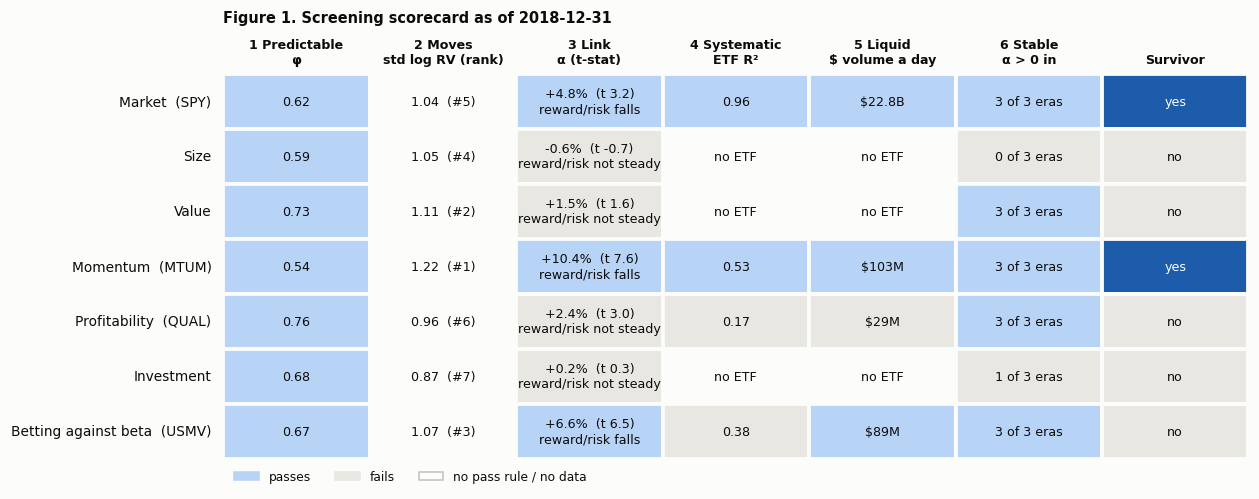

In [3]:
def money(x):
    return "n/a" if pd.isna(x) else (f"${x / 1e9:,.1f}B" if x >= 1e9 else f"${x / 1e6:,.0f}M")

def cell(r, k):
    ok_hist = r["months"] >= sc.SCREEN_RULES["min_months"]
    has_etf = r["etf"] != "none" and r["etf_days"] >= sc.SCREEN_RULES["etf_min_days"]
    n_pos = int(sum(r[f"alpha_e{i}"] > 0 for i in (1, 2, 3)))
    return {
        1: (f"{r['phi']:.2f}", r["f1"]) if ok_hist else ("n/a", None),
        2: (f"{r['std_log_rv']:.2f}  (#{r['f2_rank']:.0f})", "info") if ok_hist else ("n/a", None),
        3: (f"{r['alpha']:+.1%}  (t {r['t_alpha']:.1f})\nreward/risk " + ("falls" if r["sort_ok"] else "not steady"), r["f3"])
           if ok_hist else ("n/a", None),
        4: (f"{r['r2']:.2f}", r["f4"]) if has_etf else (("no ETF" if r["etf"] == "none" else "too new"), None),
        5: (money(r["dollar_vol"]), r["f5"]) if has_etf else (("no ETF" if r["etf"] == "none" else "too new"), None),
        6: (f"{n_pos} of 3 eras", r["f6"]) if ok_hist else ("n/a", None),
    }[k]

def scorecard(df, title):
    heads = ["1 Predictable\nφ", "2 Moves\nstd log RV (rank)", "3 Link\nα (t-stat)", "4 Systematic\nETF R²",
             "5 Liquid\n$ volume a day", "6 Stable\nα > 0 in", "Survivor"]
    fig, ax = plt.subplots(figsize=(11.5, 4.6))
    for i, (f, r) in enumerate(df.iterrows()):
        y = -i - 1
        ax.text(-0.08, y + 0.5, f"{NAMES[f]}" + (f"  ({r['etf']})" if r["etf"] != "none" else ""),
                ha="right", va="center", fontsize=9)
        for j in range(1, 8):
            txt, st = cell(r, j) if j < 7 else (("yes" if r["survivor"] else "no"), bool(r["survivor"]))
            face = DARK if (j == 7 and st) else PASS if st is True else FAIL if st is False else "#fcfcfb"
            ax.add_patch(Rectangle((j - 1, y), 1, 1, facecolor=face, edgecolor="#fcfcfb", lw=2.5))
            ax.text(j - 0.5, y + 0.5, txt, ha="center", va="center", fontsize=8.3,
                    color="white" if (j == 7 and st) else INK)
    for j, h in enumerate(heads):
        ax.text(j + 0.5, 0.15, h, ha="center", va="bottom", fontsize=8.3, fontweight="bold")
    ax.set_xlim(0, 7); ax.set_ylim(-len(df), 0); ax.axis("off")
    ax.set_title(title, loc="left", pad=34)
    ax.legend(handles=[Patch(color=PASS, label="passes"), Patch(color=FAIL, label="fails"),
                       Patch(facecolor="#fcfcfb", edgecolor=AXIS, label="no pass rule / no data")],
              loc="lower left", bbox_to_anchor=(0, -0.09), ncol=3, fontsize=8)
    fig.tight_layout()

scorecard(final, f"Figure 1. Screening scorecard as of {ASOF.date()}")

### Filter 1 — Predictable risk

**What and why.** If risk is not persistent there is nothing to forecast. This is Phase 2's gate, applied again as the first filter.

**Result.** All seven factors pass. φ runs from 0.54 (momentum) to 0.76 (profitability), and Ljung-Box rejects with p ≈ 0 everywhere. **Nothing is cut here on the full sample.** In real time it matters more (Section 4), because momentum's φ is only just above the cutoff.

### Filter 2 — Risk that moves

**What and why.** A factor whose variance never changes leaves nothing to time. The standard deviation of log RV measures how much variance moves, in a scale-free way. The spec gives no cutoff: it is a ranking, used to break ties.

**Result.** Momentum moves most (1.22), then value (1.11), betting-against-beta (1.07), size (1.05), market (1.04), profitability (0.96) and investment (0.87). The range is narrow, so nobody is "flat" and the ranking is a weak tie-breaker. Among the three survivors the order is momentum, betting-against-beta, market. No asset is cut here.

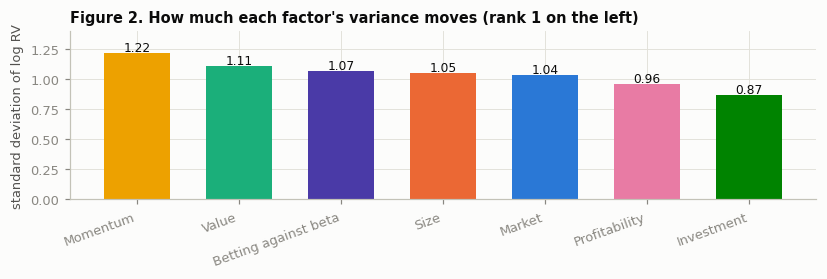

In [4]:
f2 = final[["std_log_rv", "f2_rank"]].sort_values("f2_rank")
fig, ax = plt.subplots(figsize=(7.5, 2.6))
ax.bar(range(len(f2)), f2["std_log_rv"], color=[COLORS[f] for f in f2.index], width=0.65)
for i, (f, r) in enumerate(f2.iterrows()):
    ax.text(i, r["std_log_rv"] + 0.015, f"{r['std_log_rv']:.2f}", ha="center", fontsize=8)
ax.set_xticks(range(len(f2)), [NAMES[f] for f in f2.index], rotation=20, ha="right")
ax.set_ylim(0, 1.4); ax.set_ylabel("standard deviation of log RV")
ax.set_title("Figure 2. How much each factor's variance moves (rank 1 on the left)")
fig.tight_layout()

### Filter 3 — Exploitable link

**What and why.** Volatility timing earns alpha only if reward per unit of risk, $\bar r/s^2$, falls when risk rises. If reward rises one-for-one with risk, timing gains nothing however good the forecast. This is Phase 2's Test 4: sort months into quintiles of this month's variance, check the reward-to-risk ratio of the next month, and run the spanning regression
$$\frac{c}{RV_t}\,r_{t+1} = \alpha + \beta\,r_{t+1} + \varepsilon_{t+1}$$
with White standard errors.

**Rule.** The ratio is lower in the wildest quintile than the calmest and its rank correlation with the quintile number is ≤ −0.7, **and** α > 0 with t > 1.96.

**Result.** Market, momentum and betting-against-beta pass, as in Phase 2 (Figure 1, column 3). The four cuts:

- **Size** (α −0.6%, t −0.7) and **investment** (α +0.2%, t 0.3): no alpha at all.
- **Value** (α +1.5%, t 1.6): not significant, and the ratio peaks in the second quintile instead of falling steadily.
- **Profitability** (α +2.4%, t 3.0): significant alpha, but the quintile pattern is not steady, so it fails the first half of the rule. It is the closest call, and the one most likely to flip with a slightly different sample (Section 4 shows it flickering).

**This filter does most of the work.** Every factor cut on the factor side fails filter 3. Betting-against-beta passes it and is cut later, by its ETF (filter 4).

### Filter 6 — Stable

**What and why.** A pattern that lives in one era is history, not a strategy. Filter 6 asks whether the alpha from filter 3 shows up in every era. The history up to the as-of date is cut into three equal parts, and α is re-estimated in each. The parts are thirds of whatever data exists at that date, never fixed calendar years, so no era contains data from after the date. That is what lets the walk-forward in Phase 7 run the filter in real time.

**Rule.** α > 0 in every part.

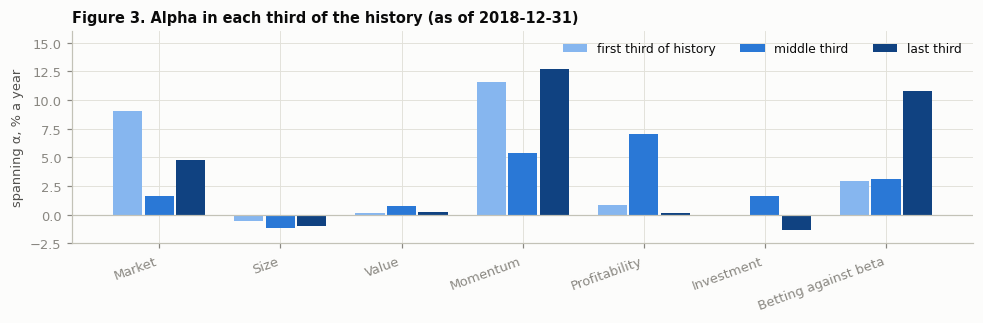

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.0))
for i, f in enumerate(final.index):
    for k in range(3):
        ax.bar(i + (k - 1) * 0.26, final.loc[f, f"alpha_e{k + 1}"] * 100, width=0.24, color=ERA_COLORS[k],
               label=["first third of history", "middle third", "last third"][k] if i == 0 else None)
ax.axhline(0, color=AXIS, lw=0.8)
ax.set_xticks(range(len(final)), [NAMES[f] for f in final.index], rotation=20, ha="right")
ax.set_ylabel("spanning α, % a year"); ax.set_ylim(-2.5, 16); ax.legend(loc="upper right", ncol=3, fontsize=8)
ax.set_title("Figure 3. Alpha in each third of the history (as of 2018-12-31)")
fig.tight_layout()

**Result.** Five factors pass (market, value, momentum, profitability, betting-against-beta). Size (alphas between −0.6% and −1.1% in all three) and investment (−0.1%, +1.6%, −1.4%) fail.

- **For the survivors the alpha is positive in every third.** Momentum has 11.6%, 5.4% and 12.7%; betting-against-beta 3.0%, 3.1% and 10.8%; the market 9.0%, 1.6% and 4.8%.
- **Value and profitability pass filter 6 but not filter 3.** Value's alphas are tiny everywhere (0.2%, 0.7%, 0.2%). Profitability's alpha comes almost entirely from the middle third (7.1% against 0.9% and 0.1%).
- **The thirds are not the Phase 2 eras.** Phase 2 used fixed calendar eras (1926–1962, 1963–1990, 1991–2018). Equal thirds of 1926–2018 end in 1957 and 1988. Profitability and investment have only half the history, so their thirds are about 18 years each against about 31 for the long series.

### Filter 4 — Systematic risk

**What and why.** Firm-specific noise earns no premium, so timing it earns nothing. The test has to ask about the ETF's *tilt*, not its market exposure, because a long-only ETF clears any R² cutoff on market exposure alone (the first version of this filter did exactly that and could not fail). So the ETF is hedged first: subtract its market beta times the market return. The leftover is regressed on market, size, value, momentum and BAB, and R² must exceed 0.5. The cutoff was suggested and fixed before the re-run. SPY is the market itself, so it is tested unhedged. French factors are systematic by construction, so the test applies to the ETFs that would actually be traded.

,etf,etf_days,beta,r2,r2_mkt,f4,f5,dollar_vol_M
factor,,,,,,,,
mkt,SPY,6527,0.990,0.958,0.947,True,True,"22,784.714"
mom,MTUM,1436,1.030,0.529,0.847,True,True,103.340
rmw,QUAL,1373,0.936,0.173,0.940,False,False,28.744
bab,USMV,1809,0.673,0.375,0.782,False,True,89.475


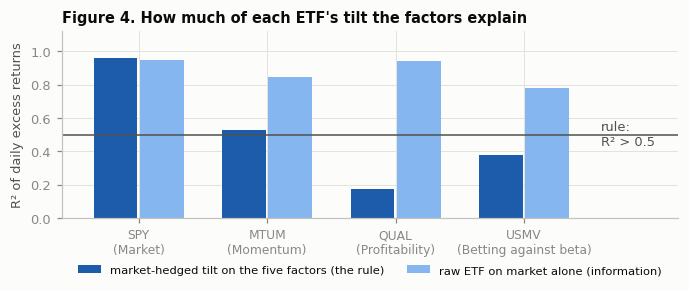

In [6]:
etf = final[final["etf"] != "none"][["etf", "etf_days", "beta", "r2", "r2_mkt", "f4", "dollar_vol", "f5"]]
etf = etf.assign(dollar_vol_M=etf["dollar_vol"] / 1e6).drop(columns="dollar_vol")
display(etf)

fig, ax = plt.subplots(figsize=(6.5, 2.8))
x = np.arange(len(etf))
ax.bar(x - 0.18, etf["r2"], width=0.34, color=DARK, label="market-hedged tilt on the five factors (the rule)")
ax.bar(x + 0.18, etf["r2_mkt"], width=0.34, color="#86b6ef", label="raw ETF on market alone (information)")
ax.axhline(sc.SCREEN_RULES["etf_r2"], color=INK2, lw=1)
ax.text(len(etf) - 0.4, sc.SCREEN_RULES["etf_r2"], "rule:\nR² > 0.5", ha="left", va="center", color=INK2)
ax.set_xticks(x, [f"{e}\n({NAMES[f]})" for f, e in zip(etf.index, etf["etf"])], fontsize=8)
ax.set_xlim(-0.6, len(etf) + 0.2); ax.set_ylim(0, 1.12); ax.set_ylabel("R² of daily excess returns")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, fontsize=7.5)
ax.set_title("Figure 4. How much of each ETF's tilt the factors explain")
fig.tight_layout()

**Result.** SPY scores 0.96 and MTUM 0.53, so both pass. **USMV (0.38) and QUAL (0.17) fail.** SPY is tested unhedged because it is the market itself.

**Reading.** The hedge is what makes the filter informative. Without it the market alone explained 0.95, 0.85, 0.78 and 0.94 of SPY, MTUM, USMV and QUAL (the light bars in Figure 4), so any of them would have passed. With it, an ETF passes only if its *tilt* is explained by the factors. MTUM's tilt is (momentum is a regressor); USMV's is mostly not. Two cautions. MTUM clears the 0.5 cutoff by a small margin (0.53 on the full sample, 0.50 at the end of 2017), so it is the one most likely to flip. And USMV is a loose stand-in for betting-against-beta (Section 1), so its low score says more about the ETF than about the factor.

### Filter 5 — Tradeable

**What and why.** Resizing the position often costs money. The spec suggests daily dollar volume above $50 million and a bid-ask spread under 5 basis points.

**Rule applied.** Median daily dollar volume (close × volume) over the last 252 trading days above $50 million. The median is robust to a few huge days.

**Rule not applied: the spread.** Phase 1 has no bid or ask. The one proxy available from daily data is the Corwin-Schultz estimator, which backs a spread out of the high and low prices. The check below shows it is not usable at this scale.

In [7]:
K = 3 - 2 * np.sqrt(2)
def corwin_schultz_bp(d):
    # Corwin-Schultz (2012) two-day high-low spread estimator, with their overnight-gap adjustment
    h, l, c = d["high"], d["low"], d["close"]
    up, dn = (l - c.shift()).clip(lower=0), (c.shift() - h).clip(lower=0)
    ha, la = h - up + dn, l - up + dn
    beta = np.log(ha / la) ** 2 + np.log(h.shift() / l.shift()) ** 2
    gamma = np.log(np.maximum(ha, h.shift()) / np.minimum(la, l.shift())) ** 2
    a = (np.sqrt(2 * beta) - np.sqrt(beta)) / K - np.sqrt(gamma / K)
    return 2 * (np.exp(a) - 1) / (1 + np.exp(a)) * 1e4

spy = ohlc[ohlc["ticker"] == "SPY"].set_index("date")
s = corwin_schultz_bp(spy)
yr = pd.DataFrame({"median estimate, bp": s.groupby(s.index.year).median(),
                   "share of days with a negative estimate": (s < 0).groupby(s.index.year).mean()}).loc[2012:]
yr.T

date,2012,2013,2014,2015,2016,2017,2018
"median estimate, bp",7.486,10.318,10.143,8.477,14.919,8.126,9.564
share of days with a negative estimate,0.448,0.440,0.401,0.472,0.429,0.382,0.450


**Why the spread is not applied.** For SPY the estimator reads about 7–15 basis points in the median, and 38–47% of its daily estimates are negative, which is impossible for a real spread. SPY's actual quoted spread is about one cent on a price of $150–250, roughly 1 basis point or less. (That figure is general knowledge, not something this repository measures.) A proxy that overstates the most liquid ETF in the world by ten times cannot be held against a 5 bp cutoff. It would only cut SPY.

So filter 5 here is the dollar-volume half only. **Spreads stay unverified.** Real quote data is needed, and the cost phase is where it belongs. Every survivor below is provisional on that.

**Result.** Median dollar volume over the final 252 days: SPY $22.8 billion, MTUM $103 million, USMV $89 million and QUAL $29 million. **QUAL fails.** Figure 5 shows how these evolved, which is what real-time screening sees.

,first day above $50M
MTUM,2018-05-29
QUAL,never
SPY,1996-12-26
USMV,2016-02-08


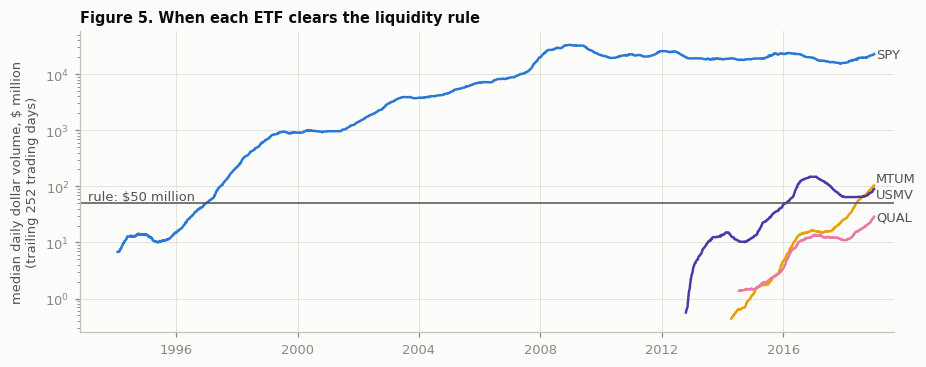

In [8]:
dv = {t: (g.set_index("date")["close"] * g.set_index("date")["volume"]).rolling(sc.SCREEN_RULES["liquidity_days"]).median() / 1e6
      for t, g in ohlc.groupby("ticker")}
fig, ax = plt.subplots(figsize=(8.5, 3.4))
for t, s_ in dv.items():
    s_ = s_.dropna(); ax.plot(s_.index, s_, color=ETF_COLORS[t], lw=1.6)
    ax.text(s_.index[-1] + pd.Timedelta(days=25), s_.iloc[-1] * {"MTUM": 1.35, "USMV": 0.8}.get(t, 1.0), t,
            color=INK2, va="center", fontsize=8.5)
ax.axhline(sc.SCREEN_RULES["dollar_volume"] / 1e6, color=INK2, lw=1)
ax.text(ohlc["date"].min(), sc.SCREEN_RULES["dollar_volume"] / 1e6 * 1.15, "rule: $50 million", color=INK2)
ax.set_yscale("log"); ax.set_ylabel("median daily dollar volume, $ million\n(trailing 252 trading days)")
ax.set_xlim(right=pd.Timestamp("2019-09-01"))
ax.set_title("Figure 5. When each ETF clears the liquidity rule")
fig.tight_layout()
first_ok = {t: s_[s_ > sc.SCREEN_RULES["dollar_volume"] / 1e6].index.min() for t, s_ in dv.items()}
pd.Series({t: (d.date() if pd.notna(d) else "never") for t, d in first_ok.items()}, name="first day above $50M").to_frame()

**Reading.** SPY has cleared the rule since December 1996 and, in the years that matter here, by a factor of several hundred. USMV first clears it in February 2016 and MTUM in May 2018. QUAL never does within the development sample: its trailing median stays below $50 million. Dollar volume understates what an ETF can absorb, because large orders are met by creating new shares, but the rule is the rule.

## 3. The survivor list and the reason for every cut

Final screen as of 2018-12-31. A factor survives only if it passes filters 1, 3, 4, 5 and 6 (filter 2 only ranks). `cut_reason` lists every filter a factor fails, in filter order.

In [9]:
survivors = final.assign(factor_name=[NAMES[f] for f in final.index])[
    ["factor_name", "etf", "survivor", "f2_rank", "cut_reason"]]
survivors["cut_reason"] = survivors["cut_reason"].replace("", "none: passes every filter")
survivors.to_csv(ROOT / "reports" / "phase3_survivors.csv")
display(survivors.sort_values(["survivor", "f2_rank"], ascending=[False, True]))

,factor_name,etf,survivor,f2_rank,cut_reason
factor,,,,,
mom,Momentum,MTUM,True,1.000,none: passes every filter
mkt,Market,SPY,True,5.000,none: passes every filter
hml,Value,none,False,2.000,"F3 exploitable link: alpha +1.5% (t 1.6), reward/risk does not fall steadily with risk; F4/F5 tradeable: no ETF in the data"
bab,Betting against beta,USMV,False,3.000,"F4 systematic: USMV hedged-tilt R² 0.38, needs > 0.5"
smb,Size,none,False,4.000,"F3 exploitable link: alpha -0.6% (t -0.7), reward/risk does not fall steadily with risk; F6 stable: alpha by era -0.6% / -1.1% / -1.0%; F4/F5 tradeable: no ETF in the data"
rmw,Profitability,QUAL,False,6.000,"F3 exploitable link: alpha +2.4% (t 3.0), reward/risk does not fall steadily with risk; F4 systematic: QUAL hedged-tilt R² 0.17, needs > 0.5; F5 liquid: QUAL dollar volume $29M, needs > $50M"
cma,Investment,none,False,7.000,"F3 exploitable link: alpha +0.2% (t 0.3), reward/risk does not fall steadily with risk; F6 stable: alpha by era -0.1% / +1.6% / -1.4%; F4/F5 tradeable: no ETF in the data"


**Survivors (2): market (SPY) and momentum (MTUM).**

| Cut | Filters failed | In short |
|---|---|---|
| Size | 3, 6, no ETF | negative alpha in every era, and no ETF in the data |
| Value | 3, no ETF | alpha 1.5% is not significant; reward/risk does not fall steadily |
| Profitability | 3, 4, 5 | alpha is significant but the pattern is not steady; QUAL's tilt is not explained by the factors and it trades too little |
| Betting against beta | 4 | passes every factor filter; its ETF, USMV, has a hedged-tilt R² of 0.38 |
| Investment | 3, 6, no ETF | no alpha, unstable sign, and no ETF in the data |

Two of the four (value and profitability) have a positive alpha that falls just short of the rules. If a later phase wants a broader portfolio, those are the candidates to revisit, with a dated change to the rules rather than a quiet exception.

**Winner's curse.** Keeping 2 of 7 means the survivors' alphas (market 4.8%, momentum 10.4%) are the best draws from a larger set, so they will look worse out of sample. Screening in real time removes the first problem (telling the walk-forward which assets worked) but not this one. The holdout is the check for it.

## 4. Screening in real time

**What and why.** Screening once on the whole development sample tells the walk-forward in advance which assets worked. The fix: re-screen every year using data up to that date only, and let an asset into the portfolio only when it passes at that date.

**The function.** `screen(panel, ohlc, asof)` slices every input to `asof` before computing anything. Two checks follow: the result is identical when the data after `asof` is removed, and the function refuses mid-month dates.

In [10]:
asof = pd.Timestamp("2000-12-29")
full = sc.screen(panel, ohlc, asof)
truncated = sc.screen(panel.loc[:asof], ohlc[ohlc["date"] <= asof], asof)
pd.testing.assert_frame_equal(full, truncated)
print(f"As of {asof.date()}: the result is identical with and without the {len(panel.loc[asof:]) - 1:,} later days.")
try:
    sc.screen(panel, ohlc, pd.Timestamp("2000-12-15"))
except ValueError as e:
    print("Mid-month date refused:", e)

As of 2000-12-29: the result is identical with and without the 4,527 later days.
Mid-month date refused: 2000-12-15 is mid-month; screen at a month's last trading day


In [11]:
years = [d for d in sc.year_ends(panel.index) if d.year >= 1936]       # 1936 = first year any factor has 10 years
RT = {d.year: sc.screen(panel, ohlc, d) for d in years}                 # about 30 seconds
print(f"{len(RT)} year-ends screened, {years[0].date()} to {years[-1].date()}")

83 year-ends screened, 1936-12-31 to 2018-12-31


**Figure 6** shows every year-end for each filter that looks at the factor's own history (1, 3 and 6) and then their combination. Blue means the factor passes at that year-end, grey that it fails, and white that it has under ten years of history.

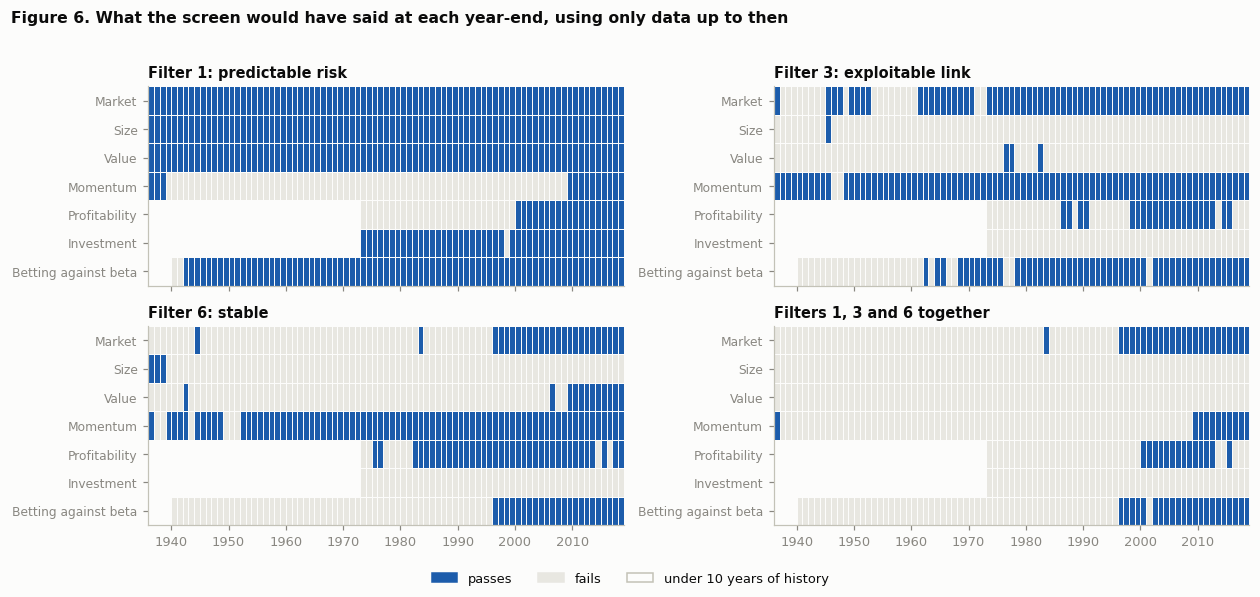

In [12]:
def state(col, combine=False):
    rows = {}
    for y, s_ in RT.items():
        ok = (s_["f1"] & s_["f3"] & s_["f6"]) if combine else s_[col]
        rows[y] = np.where(s_["months"] >= sc.SCREEN_RULES["min_months"], ok.astype(int) + 1, 0)
    return pd.DataFrame(rows, index=sc.FACTORS)

cmap = ListedColormap(["#fcfcfb", FAIL, DARK])
fig, ax = plt.subplots(2, 2, figsize=(11.5, 5.4), sharex=True)
for axi, (title, st) in zip(ax.flat, [("Filter 1: predictable risk", state("f1")), ("Filter 3: exploitable link", state("f3")),
                                      ("Filter 6: stable", state("f6")), ("Filters 1, 3 and 6 together", state(None, True))]):
    axi.pcolormesh(np.arange(st.shape[1] + 1) + 1936, np.arange(len(st) + 1), st.to_numpy(), cmap=cmap, vmin=0, vmax=2,
                   edgecolors="#fcfcfb", linewidth=0.4)
    axi.set_yticks(np.arange(len(st)) + 0.5, [NAMES[f] for f in st.index], fontsize=8); axi.invert_yaxis()
    axi.grid(False); axi.set_title(title)
fig.legend(handles=[Patch(color=DARK, label="passes"), Patch(color=FAIL, label="fails"),
                    Patch(facecolor="#fcfcfb", edgecolor=AXIS, label="under 10 years of history")],
           loc="lower center", ncol=3)
fig.suptitle("Figure 6. What the screen would have said at each year-end, using only data up to then",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout(rect=(0, 0.05, 1, 0.96))

In [13]:
adm = pd.DataFrame({y: (s_["f1"] & s_["f3"] & s_["f6"]) & (s_["months"] >= sc.SCREEN_RULES["min_months"]) for y, s_ in RT.items()})
have = pd.DataFrame({y: s_["months"] >= sc.SCREEN_RULES["min_months"] for y, s_ in RT.items()})
summary = {}
for f in sc.FACTORS:
    a, h = adm.loc[f], have.loc[f]
    run = 0
    for ok in a.iloc[::-1]:
        if not ok: break
        run += 1
    summary[NAMES[f]] = {"first screened": int(h[h].index[0]), "first admitted": int(a[a].index[0]) if a.any() else "never",
                         "year-ends admitted": f"{int(a.sum())} of {int(h.sum())}",
                         "times it entered": int((a & ~a.shift(fill_value=False)).sum()),
                         "admitted without a break since": int(a.index[-run]) if run else "not admitted in 2018"}
display(pd.DataFrame(summary).T)

def since(f, col):
    a = pd.Series({y: bool(s_.loc[f, col]) for y, s_ in RT.items()})
    run = 0
    for ok in a.iloc[::-1]:
        if not ok: break
        run += 1
    return int(a.index[-run]) if run else "not passing in 2018"
print("Year from which each filter passes without a break (the latest of the three is what delays admission):")
display(pd.DataFrame({f"filter {k[1]}": {NAMES[f]: since(f, k) for f in sc.FACTORS} for k in ("f1", "f3", "f6")}))
fails = {n: int(sum((~s_[n] & (s_["months"] >= sc.SCREEN_RULES["min_months"])).sum() for s_ in RT.values())) for n in ("f1", "f3", "f6")}
total = int(have.to_numpy().sum())
print(f"Factor-years screened: {total}. Failures by filter: F1 {fails['f1']}, F3 {fails['f3']}, F6 {fails['f6']}.")
print("Factors admitted at 1960 / 1980 / 2000 / 2018:", {y: int(adm[y].sum()) for y in (1960, 1980, 2000, 2018)})
print(f"Year-ends with at least one factor admitted: {int(adm.any().sum())} of {adm.shape[1]}")
mom = pd.Series({y: s_.loc['mom', 'phi'] for y, s_ in RT.items()})
print(f"Momentum φ at year-ends 1939-2008: from {mom.loc[1939:2008].min():.2f} to {mom.loc[1939:2008].max():.2f}; "
      f"first year above 0.5: {int(mom[mom > 0.5].loc[1940:].index.min())}")

,first screened,first admitted,year-ends admitted,times it entered,admitted without a break since
Market,1936,1983,24 of 83,2,1996
Size,1936,never,0 of 83,0,not admitted in 2018
Value,1936,never,0 of 83,0,not admitted in 2018
Momentum,1936,1936,11 of 83,2,2009
Profitability,1973,2000,14 of 46,2,not admitted in 2018
Investment,1973,never,0 of 46,0,not admitted in 2018
Betting against beta,1940,1996,22 of 79,2,2002


Year from which each filter passes without a break (the latest of the three is what delays admission):


,filter 1,filter 3,filter 6
Market,1936,1973,1996
Size,1936,not passing in 2018,not passing in 2018
Value,1936,not passing in 2018,2009
Momentum,2009,1948,1952
Profitability,2000,not passing in 2018,2017
Investment,1999,not passing in 2018,not passing in 2018
Betting against beta,1942,2002,1996


Factor-years screened: 503. Failures by filter: F1 100, F3 282, F6 326.
Factors admitted at 1960 / 1980 / 2000 / 2018: {1960: 0, 1980: 0, 2000: 3, 2018: 3}
Year-ends with at least one factor admitted: 25 of 83
Momentum φ at year-ends 1939-2008: from 0.24 to 0.46; first year above 0.5: 2009


**Result.**

- **Admission is late.** Market is first admitted at the end of 1983 and without a break from 1996. Betting-against-beta enters in 1996 and is admitted continuously from 2002. Momentum is admitted without a break from 2009. At 1960 and 1980 the portfolio would hold nothing. Only 25 of 83 year-ends admit any factor at all.
- **Filters 6 and 3 block most often** (326 and 282 of 503 factor-years), filter 1 less (100). The second table shows which filter clears last for each survivor. For the market it is filter 6: filter 3 holds from 1973, but filter 6 only from 1996. For betting-against-beta it is filter 3 (from 2002). For momentum it is filter 1 (from 2009). Early on, with 10–30 years of data, one bad third is enough to fail the sign test.
- **Momentum is held out by filter 1, not by its alpha.** It passes filters 3 and 6 for decades before it is admitted (see the table above). Filter 3 holds at every year-end except 1946 and 1947. But its level φ stayed between 0.24 and 0.46 from 1939 to 2008 and only crossed 0.5 in 2009. That is why the full-sample pass in Phase 2 (φ = 0.535) was knife-edge. A level φ is easily pulled down by single spike months (Phase 2 showed this for the market in October 1987); in logs momentum's φ is above 0.65 in every Phase 2 era.
- **The 1936 pass for momentum is a small-sample accident.** It is the first year with 10 years of data (φ 0.64), and it is gone by 1939.
- **Profitability flickers.** It is admitted at 14 of its 46 year-ends, entered twice, and is out again by 2018, which fits its borderline filter-3 result. Size, value and investment are never admitted.

**Figure 7** adds the ETF filters, which exist only from 2012. For each factor with an ETF, the state is: the factor filters fail (grey), the factor passes but its ETF does not (light blue: too illiquid, too new, or fails filter 4), or the factor is a survivor (dark blue).

,2011,2012,2013,2014,2015,2016,2017,2018
Market,survivor,survivor,survivor,survivor,survivor,survivor,survivor,survivor
Momentum,ETF fails,ETF fails,ETF fails,ETF fails,ETF fails,ETF fails,ETF fails,survivor
Profitability,ETF fails,ETF fails,factor fails,factor fails,ETF fails,factor fails,factor fails,factor fails
Betting against beta,ETF fails,ETF fails,ETF fails,ETF fails,ETF fails,ETF fails,ETF fails,ETF fails


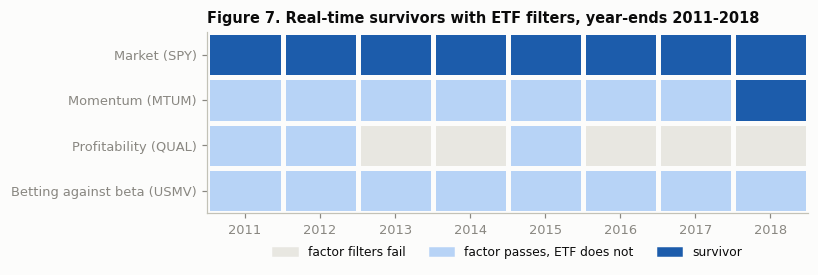

In [14]:
etf_factors = list(sc.ETF_FOR)
yrs = [y for y in RT if y >= 2011]
st = pd.DataFrame({y: [(2 if RT[y].loc[f, "survivor"] else 1 if adm.loc[f, y] else 0) for f in etf_factors] for y in yrs},
                  index=etf_factors)
fig, ax = plt.subplots(figsize=(7.5, 2.6))
ax.pcolormesh(np.arange(len(yrs) + 1) + 2011, np.arange(len(etf_factors) + 1), st.to_numpy(),
              cmap=ListedColormap([FAIL, PASS, DARK]), vmin=0, vmax=2, edgecolors="#fcfcfb", linewidth=2)
ax.set_yticks(np.arange(len(etf_factors)) + 0.5, [f"{NAMES[f]} ({sc.ETF_FOR[f]})" for f in etf_factors]); ax.invert_yaxis()
ax.set_xticks(np.arange(len(yrs)) + 2011.5, yrs); ax.grid(False)
ax.legend(handles=[Patch(color=FAIL, label="factor filters fail"), Patch(color=PASS, label="factor passes, ETF does not"),
                   Patch(color=DARK, label="survivor")], loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, fontsize=8)
ax.set_title("Figure 7. Real-time survivors with ETF filters, year-ends 2011-2018")
fig.tight_layout()
display(st.rename(index=NAMES).replace({0: "factor fails", 1: "ETF fails", 2: "survivor"}))

**Reading.** In real time the market is the only survivor through 2017, because SPY alone has a long enough, liquid enough and market-tracking record. Momentum joins at the end of 2018, once MTUM's volume clears the liquidity rule (its filter-4 test passed from 2016). Betting-against-beta never joins: its factor filters pass from 2002, but USMV fails filter 4 at every year-end (R² 0.24 to 0.38). The 2018 list is the same two as in Section 3, built up in steps: SPY throughout, MTUM from 2018.

Profitability's ETF, QUAL, fails filters 4 and 5 throughout, so the profitability row never turns dark. Betting-against-beta's row stays light because its factor passes but USMV does not.

## 5. Using the screen in Phase 7

```python
from src.data.load import load_dev, load_etf_ohlc_dev
from src import screen as sc

panel, ohlc = load_dev(), load_etf_ohlc_dev()
for asof in sc.year_ends(panel.index):                 # re-screen every year-end
    table = sc.screen(panel, ohlc, asof)               # reads only data up to asof
    eligible = list(table.index[table["survivor"]])    # trade these over the next year
```

Columns of the table: every filter's numbers and its pass flag (`f1`, `f3`, `f4`, `f5`, `f6`), the filter-2 rank (`f2_rank`, the tie-breaker), `survivor`, and `cut_reason`. `year_ends` returns each year's last trading day. Its final entry can be a partial year if the data stops mid-year, and `screen` accepts that (the frame ends at `asof`), so check that your last date is a real month-end.

The tests in `test/test_screen.py` include one that rewrites everything after `asof` with garbage and checks that the output does not change.

## 6. Caveats and decisions for you

**What the screen does not know**

1. **Spreads are unverified.** Every ETF survivor is provisional until quote data confirms spreads under 5 bp. SPY is no concern, but MTUM should be checked.
2. **Long-only ETFs are mostly market.** The market alone explains 78–95% of each raw ETF (Figure 4). Filter 4 now looks past that, but only to ask whether a tilt exists. MTUM's hedged tilt scores 0.53 against a cutoff of 0.5, and timing MTUM's variance is still largely timing the market's variance, not momentum's. Whether that is acceptable for the implementation phase, or whether the strategy should trade the factors through long-short positions instead, is a question for later phases.
3. **The ETF mapping is a judgment.** QUAL for profitability and USMV for betting-against-beta are loose matches, and filter 4 bears that out: neither tilt is explained by the factors. Size, value and investment have no ETF in the data, so even if they passed the other filters they would be cut here.
4. **ETFs are not tuned on.** They have 5–7 years before 2019, under the 10-year initial window, so no rule or cutoff was chosen from them. The one ETF-side cutoff that changed (filter 4, 0.7 to 0.5) changed because the first version could not fail, and its value was fixed before the re-run. It still decides the outcome for MTUM (in) and USMV (out), so treat that as a judgment, not a measurement.
5. **Same data as Phase 2.** On the full development sample this screen repeats what Phase 2 already showed. The evidence that matters is the walk-forward (Phase 7) and the holdout.

**Decisions I did not make for you**

6. **What to hold when nothing passes.** In real time, no factor passes before 1983 (Figure 6). A walk-forward over the long history would be in cash, or in buy-and-hold, for its first half-century. Which one is a design choice that changes what the strategy is compared with.
7. **Assets that flip in and out.** Profitability enters and leaves a few times. A rule such as "stay in unless it fails twice in a row" would calm that, at the cost of delay. I have not added one, since the spec does not ask for it.
8. **The long history has no ETFs.** Filters 4 and 5 only exist from about 2012. A full-history walk-forward can only use filters 1, 2, 3 and 6 on paper factor portfolios, and the ETF-level screen only runs from 2012. That means two walk-forwards, or a decision to evaluate on the ETF era only.
9. **Momentum's filter 1.** Applying the rule to level φ (as Phase 2's Test 1 did) holds momentum out until 2009. Applying it to φ on log RV would let it in from 1936. Both are defensible. I used levels because that is what the spec and Phase 2 say, and I do not want to change a rule after seeing its effect. If you want the log version, record it as a new dated entry in `PREREGISTRATION.md` and re-run.

**Pre-registration.** `PREREGISTRATION.md` still holds no rules. The cutoffs in `SCREEN_RULES` and the choices in Section 1 are worth recording there, including the dated filter-4 change, before Phase 7 starts. I have not edited it.